In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')

In [3]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [4]:
df.shape

(7043, 21)

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df[df['TotalCharges'].str.strip()== ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [8]:
import numpy as np

df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [10]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [11]:
df["TotalCharges"].dtype

dtype('float64')

In [12]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [13]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [14]:
df = df.drop('customerID', axis= 1)

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [16]:
cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

In [18]:
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

Training shape: (5634, 45)
Testing shape: (1409, 45)


In [19]:
#Class Weighting

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

In [20]:
rf_model.fit(X_train_encoded, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [21]:
from sklearn.metrics import accuracy_score, roc_auc_score

y_pred = rf_model.predict(X_test_encoded)
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7842441447835344
ROC-AUC: 0.8219600093001628


In [22]:
print(rf_model.classes_)

['No' 'Yes']


In [23]:
%pip install xgboost

In [24]:
y_train_xgb = y_train.map({"No": 0, "Yes": 1})
y_test_xgb = y_test.map({"No": 0, "Yes": 1})

In [25]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=(y_train_xgb == 0).sum() / (y_train_xgb == 1).sum(),
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_encoded, y_train_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [26]:
from sklearn.metrics import accuracy_score, roc_auc_score

y_pred_xgb = xgb_model.predict(X_test_encoded)
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]

print("XGBoost Accuracy:", accuracy_score(y_test_xgb, y_pred_xgb))
print("XGBoost ROC-AUC:", roc_auc_score(y_test_xgb, y_prob_xgb))

XGBoost Accuracy: 0.7544357700496807
XGBoost ROC-AUC: 0.8354594538737761


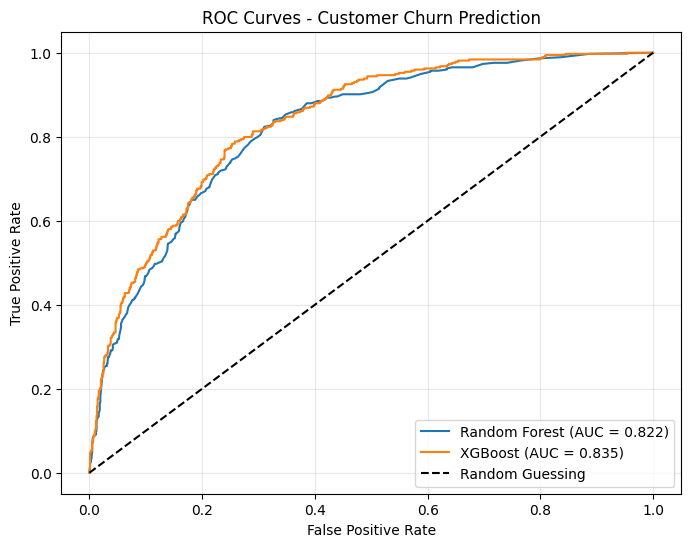

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Random Forest probabilities
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]

# ROC curve values
fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf,
    pos_label="Yes"
)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_xgb, y_prob_xgb)

# AUC scores
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_xgb = roc_auc_score(y_test_xgb, y_prob_xgb)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {auc_xgb:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
#Cross-validation

In [29]:
#randomforest

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest fold scores:", rf_scores)
print("Random Forest mean ROC-AUC:", rf_scores.mean())
print("Random Forest std:", rf_scores.std())

Random Forest fold scores: [0.81738848 0.80861931 0.82640808 0.81734606 0.84301966]
Random Forest mean ROC-AUC: 0.8225563172554826
Random Forest std: 0.011676282155903361


In [30]:
#XGBoost

from xgboost import XGBClassifier

y_train_xgb = y_train.map({"No": 0, "Yes": 1})

scale_ratio = (
    (y_train_xgb == 0).sum() /
    (y_train_xgb == 1).sum()
)

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        scale_pos_weight=scale_ratio,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_scores = cross_val_score(
    xgb_pipeline,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("XGBoost fold scores:", xgb_scores)
print("XGBoost mean ROC-AUC:", xgb_scores.mean())
print("XGBoost std:", xgb_scores.std())

XGBoost fold scores: [0.84122195 0.83162676 0.84276089 0.85346687 0.85618527]
XGBoost mean ROC-AUC: 0.8450523479193166
XGBoost std: 0.0088872411952028


In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Encoded features ke names
feature_names = preprocessor.get_feature_names_out()

# Random Forest ki feature importance
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Top 10 features
rf_top10 = rf_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print(rf_top10)

                                Feature  Importance
44              remainder__TotalCharges    0.144928
42                    remainder__tenure    0.128899
43            remainder__MonthlyCharges    0.124198
32         cat__Contract_Month-to-month    0.069718
14               cat__OnlineSecurity_No    0.038408
34               cat__Contract_Two year    0.036667
39  cat__PaymentMethod_Electronic check    0.028737
23                  cat__TechSupport_No    0.028019
12     cat__InternetService_Fiber optic    0.026457
17                 cat__OnlineBackup_No    0.017432


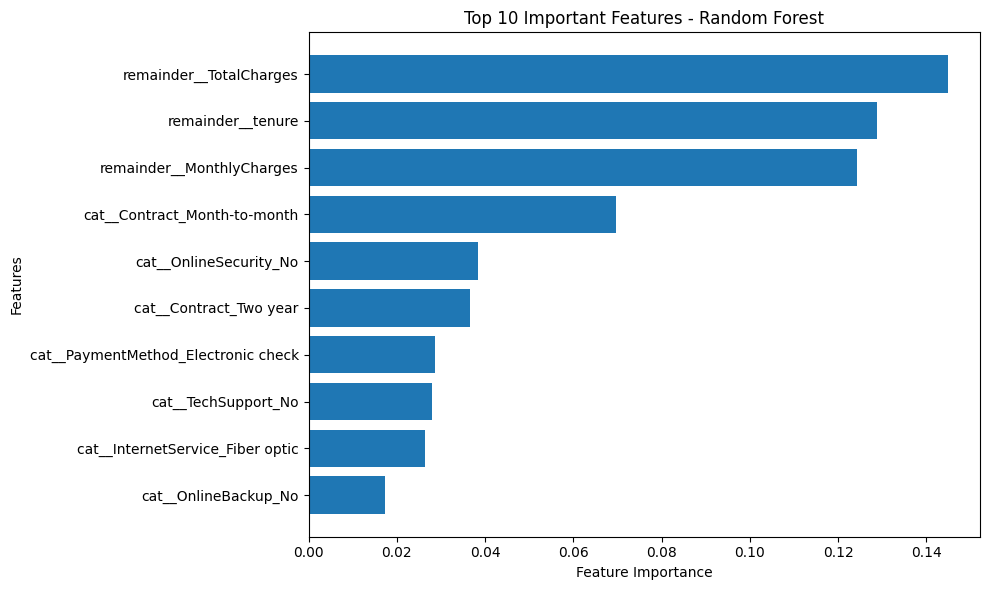

In [32]:
plt.figure(figsize=(10, 6))

plt.barh(
    rf_top10["Feature"][::-1],
    rf_top10["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [33]:
xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_top10 = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print(xgb_top10)

                                Feature  Importance
32         cat__Contract_Month-to-month    0.516461
12     cat__InternetService_Fiber optic    0.096534
14               cat__OnlineSecurity_No    0.055960
11             cat__InternetService_DSL    0.033771
31             cat__StreamingMovies_Yes    0.027632
33               cat__Contract_One year    0.020534
23                  cat__TechSupport_No    0.019835
34               cat__Contract_Two year    0.018540
19                cat__OnlineBackup_Yes    0.016704
39  cat__PaymentMethod_Electronic check    0.014940


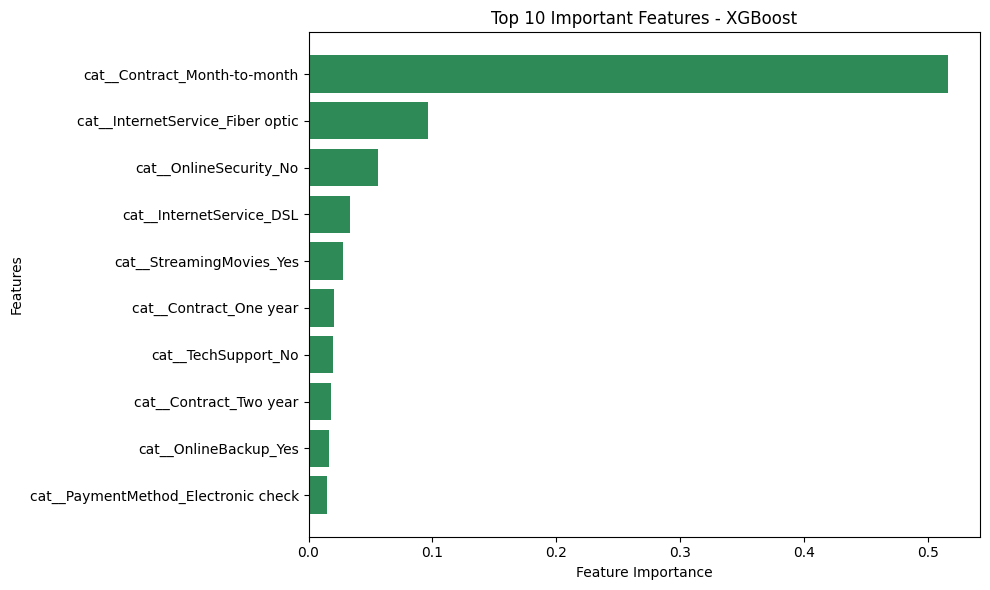

In [34]:
plt.figure(figsize=(10, 6))

plt.barh(
    xgb_top10["Feature"][::-1],
    xgb_top10["Importance"][::-1],
    color="seagreen"
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - XGBoost")
plt.tight_layout()
plt.show()